In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder

In [2]:
df = pd.read_csv('adult_with_headers (1).csv')

In [3]:
df.shape

(32561, 15)

In [4]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


# **`Data Exploration and Preprocessing:`**

**● Handle missing values as per the best practices (imputation, removal, etc.)**


In [6]:
#missing values
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,0
relationship,0
race,0
sex,0


In [7]:
#duplicates
df.duplicated().sum()

np.int64(24)

In [8]:
df.drop_duplicates(inplace=True, ignore_index=True)

In [9]:
df.duplicated().sum()

np.int64(0)

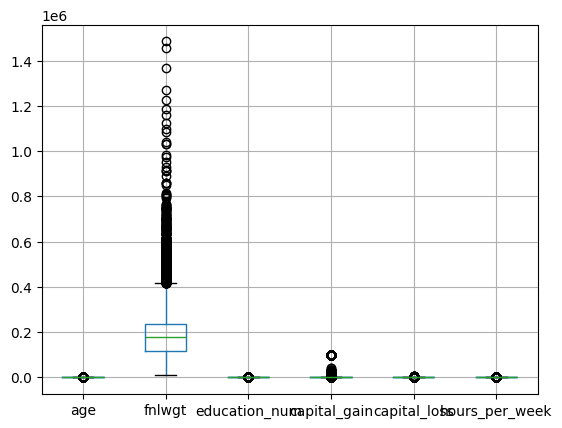

In [10]:
df.boxplot()
plt.show()

In [11]:
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int', 'float']).columns:
  outlier_capping(df, col)

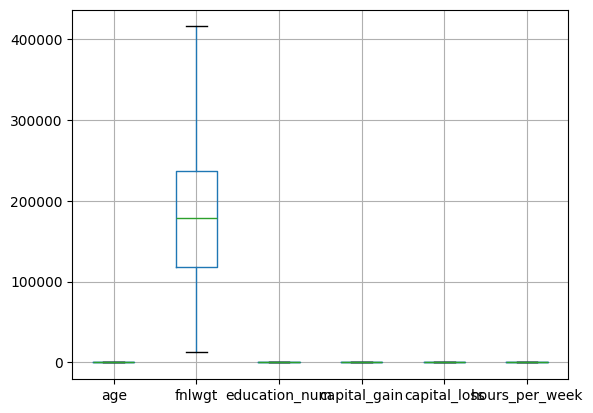

In [12]:
df.boxplot()
plt.show()

**●	Apply scaling techniques to numerical features:**

# a.	Standard Scaling  

In [13]:
target = df[['income']]
features = df.drop(columns = ['income'])

In [14]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,32.5,United-States,<=50K
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K


In [15]:
std_sca = StandardScaler()
features[['age', 'fnlwgt','capital_gain', 'capital_loss', 'hours_per_week']] = std_sca.fit_transform(features[['age', 'fnlwgt','capital_gain', 'capital_loss', 'hours_per_week']])

In [16]:
features.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,0.032472,State-gov,-1.149209,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0.0,0.0,-0.194472,United-States
1,0.844002,Self-emp-not-inc,-1.088284,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,-1.406640,United-States
2,-0.041304,Private,0.303007,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,-0.194472,United-States
3,1.065329,Private,0.503550,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,-0.194472,United-States
4,-0.779058,Private,1.593665,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,-0.194472,Cuba


# b. Min-Max Scaling

In [17]:
min_max_std = MinMaxScaler()
features[['age', 'fnlwgt','capital_gain', 'capital_loss', 'hours_per_week']] = min_max_std.fit_transform(features[['age', 'fnlwgt','capital_gain', 'capital_loss', 'hours_per_week']])

In [18]:
features.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,0.360656,State-gov,0.161680,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0.0,0.0,0.375,United-States
1,0.540984,Self-emp-not-inc,0.176044,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,0.000,United-States
2,0.344262,Private,0.504046,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,0.375,United-States
3,0.590164,Private,0.551325,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,0.375,United-States
4,0.180328,Private,0.808324,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,0.375,Cuba


**●	Discuss the scenarios where each scaling technique is preferred and why.**

Standard Scaling is used for numerical continuous features and produces both positive and negative values within the range(-3 to 3), while Min-Max Scaling is used when features need to be scaled within a fixed range of 0 to 1.

**Explanation:**
---

The dataset was first loaded. It was checked for missing values and duplicate records, and duplicate rows were dropped. Outliers in numerical columns were identified using boxplots and handled through outlier capping.

Feature scaling was then applied to selected continuous numerical columns. Standard Scaling was used to standardize the data around zero, while Min-Max Scaling was applied to scale the values between 0 and 1. Standard Scaling is preferred for scale-sensitive algorithms, whereas Min-Max Scaling is useful when features need to be within a fixed range.

# **`2. Encoding Techniques:`**







In [19]:
#showing all numerical columns
num_cols_original = df.select_dtypes(include = ['int64', 'float64']).columns
num_cols_original

Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week'],
      dtype='object')

In [20]:
#showing all the categorical columns
cat_cols = df.select_dtypes(include =['object']).columns
cat_cols

Index(['workclass', 'education', 'marital_status', 'occupation',
       'relationship', 'race', 'sex', 'native_country', 'income'],
      dtype='object')

In [21]:
#nunique to count no of categories in each categorical columns and storing it in cat_counts for convience
cat_counts = df[cat_cols].nunique()
cat_counts

,0
workclass,9
education,16
marital_status,7
occupation,15
relationship,6
race,5
sex,2
native_country,42
income,2


**●	Apply One-Hot Encoding to categorical variables with less than 5 categories.**

In [22]:
#categorical columns with less than 5 categories
col_less_than_5 = cat_counts[cat_counts < 5]
col_less_than_5

,0
sex,2
income,2


In [23]:
#we have to columns with less than 5 categories, but here we will only take sec column as income is our target we can't label it
one_hot = OneHotEncoder()
one_hot.fit_transform(df[['sex']]).toarray()

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       ...,
       [1., 0.],
       [0., 1.],
       [1., 0.]])

In [24]:
#coverting the above array into dataframe and sex columns are named as female and male as it has 2 categories
df1 = pd.DataFrame(one_hot.fit_transform(df[['sex']]).toarray(), columns = ['Female', 'Male'])
df1

,Female,Male
0,0.0,1.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,1.0,0.0
...,...,...
32532,1.0,0.0
32533,0.0,1.0
32534,1.0,0.0
32535,0.0,1.0


In [25]:
#joining df1 with df to get output in original data and saving it in df2
df2 = df.join(df1)
df2

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,Female,Male
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,32.5,United-States,<=50K,0.0,1.0
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32532,27.0,Private,257302.0,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,0.0,0.0,38.0,United-States,<=50K,1.0,0.0
32533,40.0,Private,154374.0,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0.0,0.0,40.0,United-States,>50K,0.0,1.0
32534,58.0,Private,151910.0,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,0.0,0.0,40.0,United-States,<=50K,1.0,0.0
32535,22.0,Private,201490.0,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,Male,0.0,0.0,32.5,United-States,<=50K,0.0,1.0


In [26]:
#now dropping original sex column as it is encoded and as 2 separate columns(female, male)
df2.drop(columns = ['sex'], inplace = True)

In [27]:
#replacing original df with this encoded dataframe for convience
df = df2.copy()
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,income,Female,Male
0,39.0,State-gov,77516.0,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
1,50.0,Self-emp-not-inc,83311.0,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,0.0,0.0,32.5,United-States,<=50K,0.0,1.0
2,38.0,Private,215646.0,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
3,53.0,Private,234721.0,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,0.0,0.0,40.0,United-States,<=50K,0.0,1.0
4,28.0,Private,338409.0,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,0.0,0.0,40.0,Cuba,<=50K,1.0,0.0


**●	Use Label Encoding for categorical variables with more than 5 categories.**


In [28]:
#categorical columns with more than  or equal to 5 categories
col_more_than_5 = cat_counts[cat_counts >= 5]
col_more_than_5

,0
workclass,9
education,16
marital_status,7
occupation,15
relationship,6
race,5
native_country,42


In [29]:
le = LabelEncoder()


In [30]:
#using for loop, to label all the columns which has more than 5 categories
for col in col_more_than_5.index:
  df[col] = le.fit_transform(df[col])

In [31]:
#all categorical columns change to numerical ones
df[col_more_than_5.index].head()

,workclass,education,marital_status,occupation,relationship,race,native_country
0,7,9,4,1,1,4,39
1,6,9,2,4,0,4,39
2,4,11,0,6,1,4,39
3,4,1,2,6,0,2,39
4,4,9,2,10,5,2,5


**●	Load the dataset and conduct basic data exploration (summary statistics, missing values, data types).**


In [32]:
#I have already loaded dataset and also basic EDA like handling missing values, dropping duplicates and outliers
#summary statistics
df.describe()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,capital_gain,capital_loss,hours_per_week,native_country,Female,Male
count,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.000000,32537.0,32537.0,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.559855,3.868734,186824.961736,10.297507,10.125165,2.611427,6.572856,1.446538,3.665827,0.0,0.0,41.203246,36.721579,0.330762,0.669238
std,13.554847,1.456445,95118.115529,3.870142,2.459436,1.506301,4.229521,1.607064,0.848847,0.0,0.0,6.187352,7.820732,0.470495,0.470495
min,17.000000,0.000000,12285.000000,0.000000,4.500000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,32.500000,0.000000,0.000000,0.000000
25%,28.000000,4.000000,117827.000000,9.000000,9.000000,2.000000,3.000000,0.000000,4.000000,0.0,0.0,40.000000,39.000000,0.000000,0.000000
50%,37.000000,4.000000,178356.000000,11.000000,10.000000,2.000000,7.000000,1.000000,4.000000,0.0,0.0,40.000000,39.000000,0.000000,1.000000
75%,48.000000,4.000000,236993.000000,12.000000,12.000000,4.000000,10.000000,3.000000,4.000000,0.0,0.0,45.000000,39.000000,1.000000,1.000000
max,78.000000,8.000000,415742.000000,15.000000,16.000000,6.000000,14.000000,5.000000,4.000000,0.0,0.0,52.500000,41.000000,1.000000,1.000000


In [33]:
#datatypes
df.dtypes

,0
age,float64
workclass,int64
fnlwgt,float64
education,int64
education_num,float64
marital_status,int64
occupation,int64
relationship,int64
race,int64
capital_gain,float64


**●	Discuss the pros and cons of One-Hot Encoding and Label Encoding.**

**One-Hot Encoding**

Pros:-

Does not create any ordinal relationship between categories.

Works well for categorical features with a small number of categories.

Cons:-

Increases the number of features, leading to high dimensionality.

Requires more memory and computational resources.




**Label Encoding**

Pros:-

Simple to implement and memory efficient.

Suitable for features with a large number of categories.

Cons:-

Introduces an artificial ordinal relationship between categories.

Can mislead models that assume numerical order.

**Explanation:**
---

In this, categorical variables were identified and analyzed based on the number of unique categories. Features with fewer than five categories were encoded using One-Hot Encoding. Features with a larger number of categories were encoded using Label Encoding to reduce dimensionality and maintain computational efficiency.performed basic EDA like data types and summary statistics. These encoding techniques help convert categorical data into a suitable numerical format for machine learning models.

# **`3. Feature Engineering:`**



**●	Create at least 2 new features that could be beneficial for the model. Explain the rationale behind your choices.**


In [34]:
df['Total_Capital'] = df['capital_gain'] - df['capital_loss']

In [35]:
df['Education_age_ratio'] = df['education_num'] / df['age']

The feature capital_total was created to show the overall capital effect by combining capital gain and capital loss into one value. This gives a clearer picture of a person’s financial situation. The feature education_age_ratio was created to relate a person’s education level to their age, which helps in understanding their potential earning capacity. These features make the data more meaningful and help the model learn better.

These two features help the model by capturing important relationships that are not directly visible in the original data.

**●	Apply a transformation (e.g., log transformation) to at least one skewed numerical feature and justify your choice.**

In [36]:
num_cols_original

Index(['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss',
       'hours_per_week'],
      dtype='object')

In [37]:
#skewness analysis should be done only one original continuous nunerical columns, not numerical columns after encoding
df[num_cols_original].skew()

,0
age,0.513435
fnlwgt,0.548158
education_num,-0.033530
capital_gain,0.000000
capital_loss,0.000000
hours_per_week,0.438212


In [38]:
#selecting 'fnlwgt' to apply log transformation
#skewness value is different because earlier features were raw and here fnlwgt got capped
df['fnlwgt'].skew()

np.float64(0.5481580296455432)

In [39]:
#applying log transformation
df['log_fnlwgt'] = np.log1p(df['fnlwgt'])

In [40]:
df[['fnlwgt', 'log_fnlwgt']].head()

,fnlwgt,log_fnlwgt
0,77516.0,11.258253
1,83311.0,11.330348
2,215646.0,12.281398
3,234721.0,12.366157
4,338409.0,12.732013


**Explanation:**
---

In this task, new features were created from existing numerical variables to improve the model’s understanding of the data. The feature capital_total was created by combining capital gain and capital loss to represent the overall capital effect of an individual. The feature education_age_ratio was created to relate education level to age, which helps reflect a person’s potential earning capacity.

Next skewness in numerical features was analyzed, and fnlwgt was identified as a skewed column. A log transformation was applied to reduce skewness and make the data distribution more balanced. Overall, these feature engineering steps helped make the dataset more meaningful and suitable for better model performance.